Step 1: Load Required Libraries

In [40]:
library(tidyverse)
library(caret)
library(corrplot)
library(randomForest)
library(ggplot2)



Step 2: Import Dataset

In [3]:
# Corrected code with the missing closing quotation mark
shopper <- read.csv("C:/Users/tasmi/OneDrive/Desktop/Data Analyst CV/Coursera Project/R project/Online shopping/online_shoppers_intention.csv")

# Preview data structure and summaries
head(shopper)
str(shopper)
summary(shopper)


Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0,0,1,0.000000,0.20000000,0.2000000,0,0,Feb,1,1,1,1,Returning_Visitor,FALSE,FALSE
0,0,0,0,2,64.000000,0.00000000,0.1000000,0,0,Feb,2,2,1,2,Returning_Visitor,FALSE,FALSE
0,0,0,0,1,0.000000,0.20000000,0.2000000,0,0,Feb,4,1,9,3,Returning_Visitor,FALSE,FALSE
0,0,0,0,2,2.666667,0.05000000,0.1400000,0,0,Feb,3,2,2,4,Returning_Visitor,FALSE,FALSE
0,0,0,0,10,627.500000,0.02000000,0.0500000,0,0,Feb,3,3,1,4,Returning_Visitor,TRUE,FALSE
0,0,0,0,19,154.216667,0.01578947,0.0245614,0,0,Feb,2,2,1,3,Returning_Visitor,FALSE,FALSE


'data.frame':	12330 obs. of  18 variables:
 $ Administrative         : int  0 0 0 0 0 0 0 1 0 0 ...
 $ Administrative_Duration: num  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational          : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational_Duration : num  0 0 0 0 0 0 0 0 0 0 ...
 $ ProductRelated         : int  1 2 1 2 10 19 1 0 2 3 ...
 $ ProductRelated_Duration: num  0 64 0 2.67 627.5 ...
 $ BounceRates            : num  0.2 0 0.2 0.05 0.02 ...
 $ ExitRates              : num  0.2 0.1 0.2 0.14 0.05 ...
 $ PageValues             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ SpecialDay             : num  0 0 0 0 0 0 0.4 0 0.8 0.4 ...
 $ Month                  : Factor w/ 10 levels "Aug","Dec","Feb",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ OperatingSystems       : int  1 2 4 3 3 2 2 1 2 2 ...
 $ Browser                : int  1 2 1 2 3 2 4 2 2 4 ...
 $ Region                 : int  1 1 9 2 1 1 3 1 2 1 ...
 $ TrafficType            : int  1 2 3 4 4 3 3 5 3 2 ...
 $ VisitorType            : Factor w/ 3 levels "New_Visit

 Administrative   Administrative_Duration Informational    
 Min.   : 0.000   Min.   :   0.00         Min.   : 0.0000  
 1st Qu.: 0.000   1st Qu.:   0.00         1st Qu.: 0.0000  
 Median : 1.000   Median :   7.50         Median : 0.0000  
 Mean   : 2.315   Mean   :  80.82         Mean   : 0.5036  
 3rd Qu.: 4.000   3rd Qu.:  93.26         3rd Qu.: 0.0000  
 Max.   :27.000   Max.   :3398.75         Max.   :24.0000  
                                                           
 Informational_Duration ProductRelated   ProductRelated_Duration
 Min.   :   0.00        Min.   :  0.00   Min.   :    0.0        
 1st Qu.:   0.00        1st Qu.:  7.00   1st Qu.:  184.1        
 Median :   0.00        Median : 18.00   Median :  598.9        
 Mean   :  34.47        Mean   : 31.73   Mean   : 1194.8        
 3rd Qu.:   0.00        3rd Qu.: 38.00   3rd Qu.: 1464.2        
 Max.   :2549.38        Max.   :705.00   Max.   :63973.5        
                                                                


Step 3: Data Cleaning

Check Missing Values

In [4]:
colSums(is.na(shopper))

Administrative Administrative_Duration           Informational 
                      0                       0                       0 
 Informational_Duration          ProductRelated ProductRelated_Duration 
                      0                       0                       0 
            BounceRates               ExitRates              PageValues 
                      0                       0                       0 
             SpecialDay                   Month        OperatingSystems 
                      0                       0                       0 
                Browser                  Region             TrafficType 
                      0                       0                       0 
            VisitorType                 Weekend                 Revenue 
                      0                       0                       0

Convert Variables

In [5]:
shopper$Revenue <- as.factor(shopper$Revenue)
shopper$Weekend <- as.factor(shopper$Weekend)
shopper$VisitorType <- as.factor(shopper$VisitorType)
shopper$Month <- as.factor(shopper$Month)

Step 4: Exploratory Data Analysis

Revenue Distribution

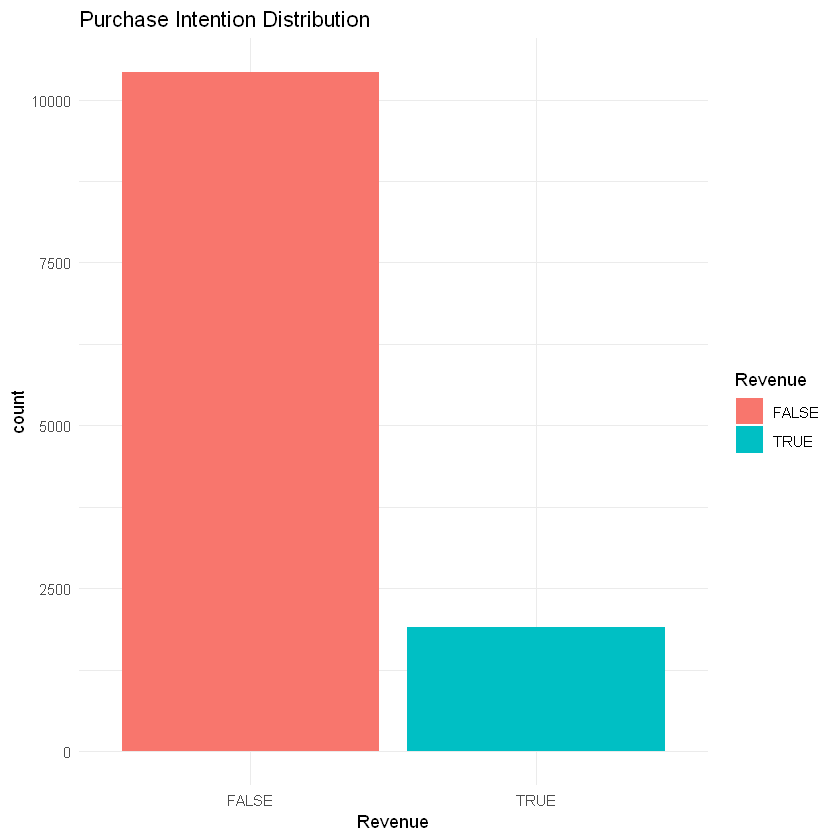

In [6]:
ggplot(shopper, aes(x=Revenue, fill=Revenue))+
  geom_bar()+
  theme_minimal()+
  ggtitle("Purchase Intention Distribution")

Insight

Most visitors do not make a purchase.

Visitor Type Analysis

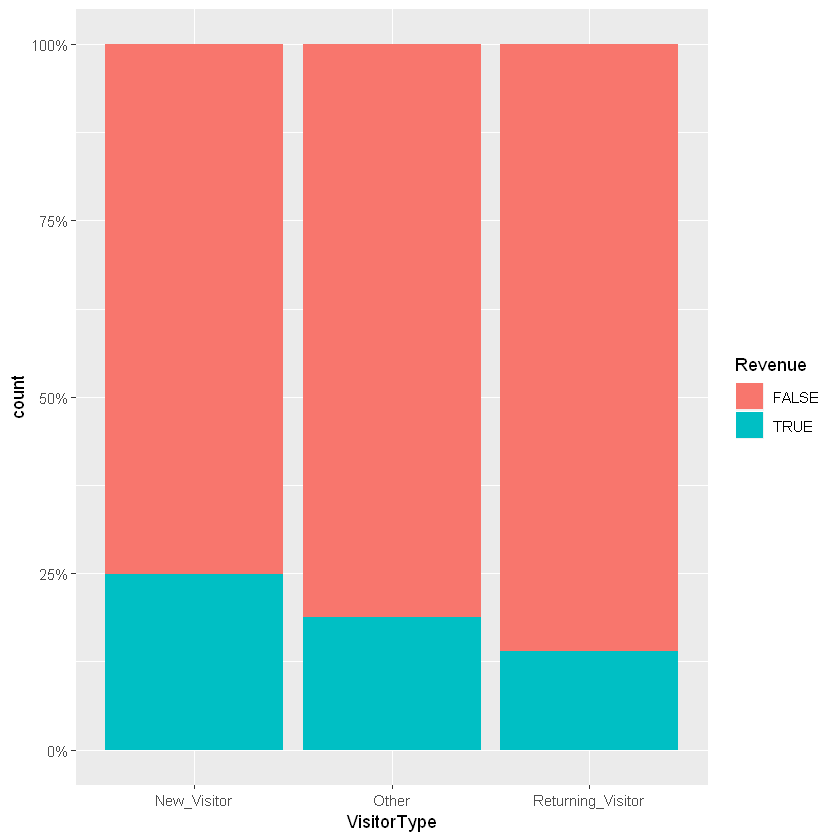

In [7]:
ggplot(shopper,
       aes(x=VisitorType,
           fill=Revenue))+
  geom_bar(position="fill")+
  scale_y_continuous(labels=scales::percent)

Insight

Returning visitors have a higher conversion rate.

Monthly Revenue Trend

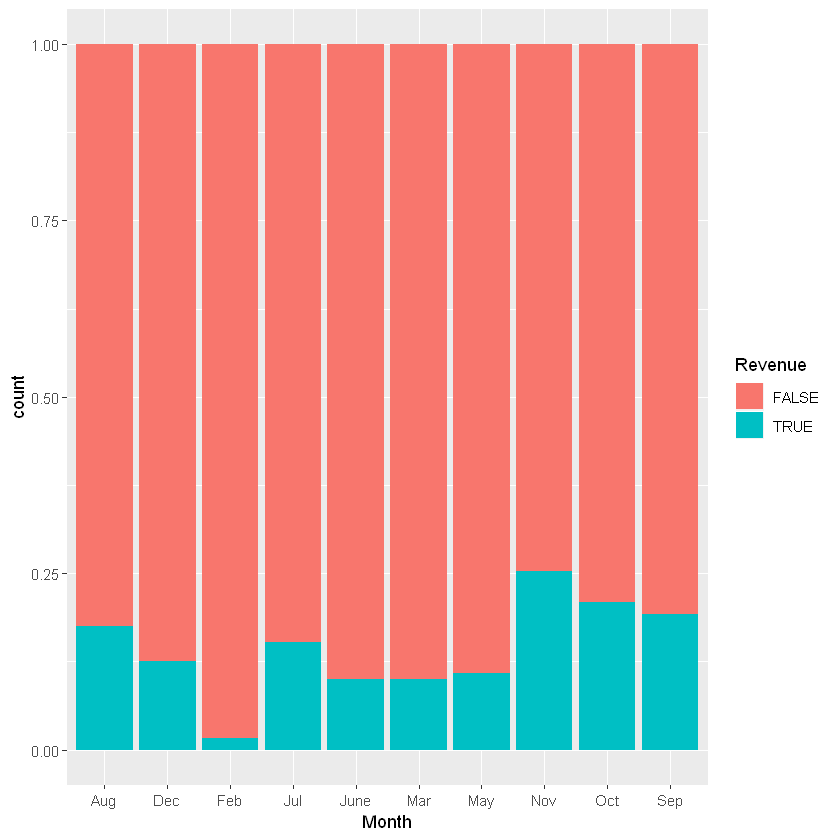

In [8]:
ggplot(shopper,
       aes(Month,
           fill=Revenue))+
  geom_bar(position="fill")

Insight

Shopping activity increases during holiday seasons

Correlation Matrix

Step 5: Data Preprocessing
Train-Test Split

In [11]:
set.seed(123)

trainIndex <- createDataPartition(
  shopper$Revenue,
  p=0.8,
  list=FALSE)

train <- shopper[trainIndex, ]
test <- shopper[-trainIndex, ]

Feature Scaling

In [12]:
preProc <- preProcess(
  train,
  method=c("center","scale"))

train_scaled <- predict(preProc, train)
test_scaled <- predict(preProc, test)

In [ ]:
Step 6: Build Machine Learning Models
Logistic Regression

In [13]:
log_model <- glm(
  Revenue~.,
  data=train,
  family="binomial")

summary(log_model)


Call:
glm(formula = Revenue ~ ., family = "binomial", data = train)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-5.8958  -0.4720  -0.3368  -0.1707   3.3936  

Coefficients:
                               Estimate Std. Error z value Pr(>|z|)    
(Intercept)                  -1.393e+00  2.215e-01  -6.290 3.18e-10 ***
Administrative                1.377e-02  1.225e-02   1.124 0.261034    
Administrative_Duration      -1.474e-04  2.167e-04  -0.680 0.496533    
Informational                 2.598e-02  2.990e-02   0.869 0.384783    
Informational_Duration        9.383e-05  2.472e-04   0.380 0.704212    
ProductRelated                7.141e-04  1.306e-03   0.547 0.584575    
ProductRelated_Duration       8.260e-05  3.117e-05   2.650 0.008051 ** 
BounceRates                  -3.555e+00  3.622e+00  -0.982 0.326289    
ExitRates                    -1.584e+01  2.661e+00  -5.951 2.66e-09 ***
PageValues                    7.750e-02  2.574e-03  30.103  < 2e-16 ***
SpecialDay

Random Forest Model

In [16]:
set.seed(123)

rf_model <- randomForest(
  Revenue~.,
  data=train,
  ntree=200)

rf_model


Call:
 randomForest(formula = Revenue ~ ., data = train, ntree = 200) 
               Type of random forest: classification
                     Number of trees: 200
No. of variables tried at each split: 4

        OOB estimate of  error rate: 9.53%
Confusion matrix:
      FALSE TRUE class.error
FALSE  8023  315  0.03777884
TRUE    625  902  0.40929928

Predictions

In [21]:
predict(rf_model, newdata = test, type = "response")


In [22]:
predict(rf_model, newdata = test, type = "prob")


In [23]:
predict(rf_model, newdata = test, type = "vote")


Feature Importance

In [28]:
importance(rf_model)

varImpPlot(rf_model)